# Endangered Languages: One-Hot Encoding + Linear Regression

This notebook explores `languages.csv` (endangered-languages data) and answers the
question you asked: **does one-hot encoding a categorical column "unlock" linear
regression on it?**

Short answer: one-hot encoding lets a categorical column be *used* by linear
regression (it turns category labels into numeric 0/1 columns), but it doesn't make
the relationship meaningful on its own. We'll build the model, measure it honestly,
and talk about why it ends up weak here.

Sections:
1. Load Data
2. Explore Data (incl. handling missing values)
3. One-Hot Encode `Degree of endangerment`
4. Linear Regression (endangerment -> number of speakers)
5. Bonus: Log-Transformed Target
6. Takeaways

Run the cells top-to-bottom with your venv's kernel selected (kernel picker, top right).

## 1. Load Data

Just read the CSV with pandas. The columns are:
- `ID` - a numeric identifier (not useful for modeling)
- `Name in English` - the language name (not useful for modeling, too many unique values)
- `Degree of endangerment` - a *categorical* label like "Vulnerable", "Definitely endangered", etc.
- `Number of speakers` - our numeric target

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("languages.csv")
df.head()

,ID,Name in English,Degree of endangerment,Number of speakers
0,1022,South Italian,Vulnerable,7500000.0
1,1023,Sicilian,Vulnerable,5000000.0
2,383,Low Saxon,Vulnerable,4800000.0
3,335,Belarusian,Vulnerable,4000000.0
4,382,Lombard,Definitely endangered,3500000.0


## 2. Explore Data

Before modeling anything, look at the shape of the data: how many rows, what types,
what the categories are, and whether anything is missing.

In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 2722 entries, 0 to 2721
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      2722 non-null   int64  
 1   Name in English         2722 non-null   str    
 2   Degree of endangerment  2722 non-null   str    
 3   Number of speakers      2539 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 85.2 KB


,ID,Number of speakers
count,2722.000000,2.539000e+03
mean,1362.501102,5.365890e+04
std,785.919949,3.114620e+05
min,2.000000,0.000000e+00
25%,682.250000,5.000000e+01
50%,1362.500000,8.000000e+02
75%,2042.750000,6.872000e+03
max,2724.000000,7.500000e+06


### Check for missing values

Real-world data is almost never perfectly clean. `df.isna().sum()` counts missing
values per column — worth checking before you build anything on top of this data.

In [3]:
df.isna().sum()

ID                          0
Name in English             0
Degree of endangerment      0
Number of speakers        183
dtype: int64

Some rows are missing `Number of speakers`. Since that's exactly the column we want
to predict, a row with no value there is useless for training *and* scikit-learn
will flat-out refuse to fit on a target containing NaN (you'll see
`ValueError: Input y contains NaN.` if you try). So we drop those rows now and use
the cleaned `df` for everything that follows.

(If a feature column had missing values instead of the target, you'd have more options —
drop the rows, drop the column, or impute a fill value — but for a missing *target* in a
supervised learning problem, dropping is really the only sound choice.)

In [4]:
print(f"Rows before dropping missing targets: {len(df)}")
df = df.dropna(subset=["Number of speakers"]).reset_index(drop=True)
print(f"Rows after dropping missing targets:  {len(df)}")

Rows before dropping missing targets: 2722
Rows after dropping missing targets:  2539


In [5]:
# How many languages fall into each endangerment category?
df["Degree of endangerment"].value_counts()

Degree of endangerment
Definitely endangered    635
Vulnerable               611
Critically endangered    544
Severely endangered      505
Extinct                  244
Name: count, dtype: int64

Notice the `"Extinct"` category — it's worth checking what `Number of speakers`
looks like there, since "extinct" strongly suggests `0`.

In [6]:
print(f"Total rows with 0 speakers: {(df['Number of speakers'] == 0).sum()}")
df.loc[df["Number of speakers"] == 0, "Degree of endangerment"].value_counts()

Total rows with 0 speakers: 257


Degree of endangerment
Extinct                  239
Critically endangered     12
Definitely endangered      4
Severely endangered        1
Vulnerable                 1
Name: count, dtype: int64

Mostly `"Extinct"`, which makes sense — but notice a handful of rows in *other*
categories (e.g. "Critically endangered") also show `0`. Those are more likely
"no reliable speaker count was ever recorded" than "literally zero living speakers" —
another reminder that a `0` in a dataset isn't automatically trustworthy just because
it's not `NaN`. Either way, the practical issue is the same: `log10(0)` is undefined
(`-infinity`), so when we log-transform speaker counts later we'll need to set all of
these rows aside, regardless of category.

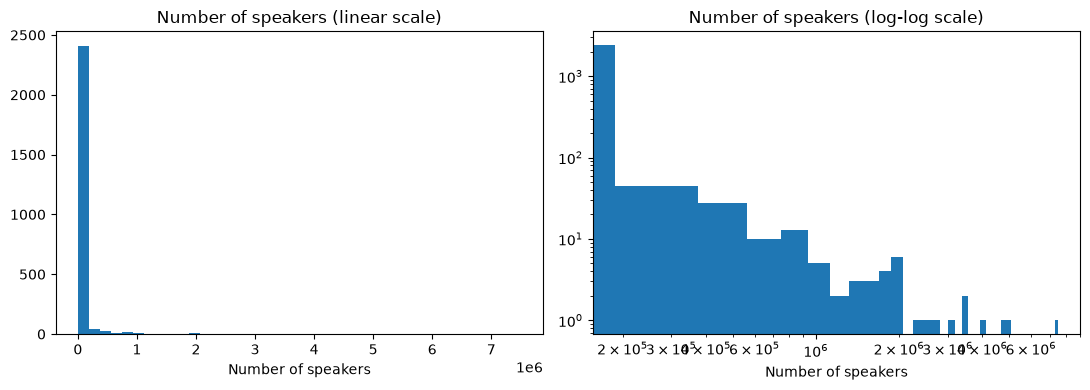

In [7]:
# Number of speakers is usually wildly skewed (a few languages have millions of
# speakers, most have very few), so look at it on a log scale.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["Number of speakers"], bins=40)
axes[0].set_title("Number of speakers (linear scale)")
axes[0].set_xlabel("Number of speakers")

axes[1].hist(df["Number of speakers"], bins=40)
axes[1].set_yscale("log")
axes[1].set_xscale("log")
axes[1].set_title("Number of speakers (log-log scale)")
axes[1].set_xlabel("Number of speakers")

plt.tight_layout()
plt.show()

Notice how spread out `Number of speakers` is — it spans several orders of
magnitude. That matters later: linear regression tries to minimize *squared* error, so
a few languages with millions of speakers will dominate the fit unless we're careful.

It's also worth a quick look at whether endangerment category and speaker count line up
at all, before we build any model.

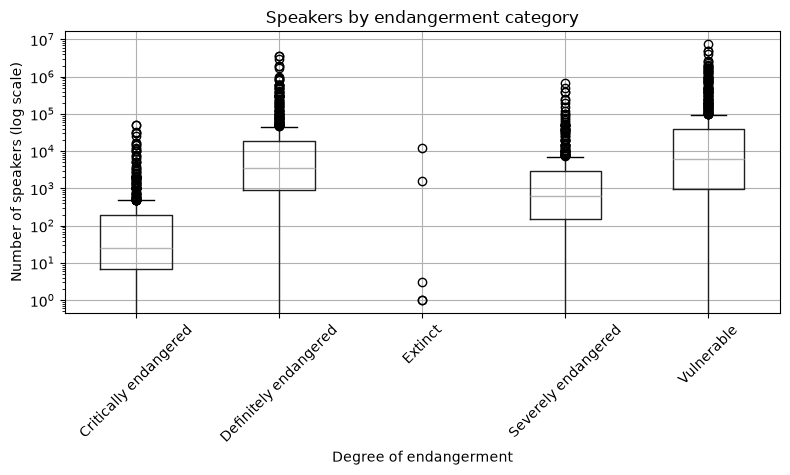

In [8]:
df.boxplot(column="Number of speakers", by="Degree of endangerment", rot=45, figsize=(8, 5))
plt.yscale("log")
plt.ylabel("Number of speakers (log scale)")
plt.title("Speakers by endangerment category")
plt.suptitle("")
plt.tight_layout()
plt.show()

There's a rough trend (categories like "Critically endangered" skew toward fewer
speakers), but there's also *huge* overlap and spread within each category. Keep that
picture in mind — it previews why the regression's $R^2$ will be modest.

## 3. One-Hot Encode `Degree of endangerment`

`Degree of endangerment` is text, like `"Vulnerable"` or `"Critically endangered"`.
Linear regression only understands numbers, and it can't treat text categories as if
they were ordered quantities (e.g. it shouldn't assume "Vulnerable" < "Extinct" the way
it would assume `1 < 2`).

**One-hot encoding** solves the "it's not a number" problem (not the "is there a real
relationship" problem) by turning one categorical column with $k$ categories into $k$
binary (0/1) columns — one per category. A row gets a `1` in the column matching its
category and `0` everywhere else. Now each category is just another numeric input the
regression can assign a coefficient to.

`pandas.get_dummies` does this in one line.

In [9]:
one_hot = pd.get_dummies(df["Degree of endangerment"], prefix="endangerment")
one_hot.head()

,endangerment_Critically endangered,endangerment_Definitely endangered,endangerment_Extinct,endangerment_Severely endangered,endangerment_Vulnerable
0,False,False,False,False,True
1,False,False,False,False,True
2,False,False,False,False,True
3,False,False,False,False,True
4,False,True,False,False,False


One thing to watch for: if you include *all* $k$ dummy columns plus an intercept,
the columns are perfectly collinear (they always sum to 1), which is redundant
information for the model. The common fix is `drop_first=True`, which drops one
category to use as the "baseline" that the intercept represents. The dropped
category's effect is folded into the intercept, and every other coefficient is
interpreted *relative to it*.

In [10]:
X = pd.get_dummies(df["Degree of endangerment"], prefix="endangerment", drop_first=True)
y = df["Number of speakers"]

X.head()

,endangerment_Definitely endangered,endangerment_Extinct,endangerment_Severely endangered,endangerment_Vulnerable
0,False,False,False,True
1,False,False,False,True
2,False,False,False,True
3,False,False,False,True
4,True,False,False,False


## 4. Linear Regression

Now we have a numeric design matrix `X` (one-hot columns) and a numeric target `y`
(speaker counts), with no missing values left in either. Let's split into train/test
sets, fit `LinearRegression`, and look at the results honestly — including the bad
news.

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept (baseline category's predicted speakers):", model.intercept_)
for col, coef in zip(X.columns, model.coef_):
    print(f"{col:40s} {coef:,.1f}")

Intercept (baseline category's predicted speakers): 872.4636363639802
endangerment_Definitely endangered       67,994.1
endangerment_Extinct                     -864.2
endangerment_Severely endangered         9,027.2
endangerment_Vulnerable                  164,839.9


In [12]:
train_r2 = r2_score(y_train, model.predict(X_train))
test_r2 = r2_score(y_test, model.predict(X_test))

print(f"Train R^2: {train_r2:.4f}")
print(f"Test R^2:  {test_r2:.4f}")

Train R^2: 0.0371
Test R^2:  -0.0816


If your $R^2$ values are small (even close to zero, or negative on the test set),
that's not a bug — it's an honest result. Here's why:

- One-hot encoding only gave the model a handful of categories to work with. Since
  every language *within* a category shares the exact same one-hot row, the model can
  only ever predict the **average speaker count for that category** — it has no way
  to tell "South Italian (7.5M speakers)" apart from another "Vulnerable" language with
  a few thousand speakers. Both get the identical prediction.
- Number of speakers varies by orders of magnitude *within* every single category (see
  the boxplot above), so "the category average" is a weak predictor of any individual
  language's speaker count.
- Conceptually, the causality likely runs backwards from what we're modeling: a
  language's endangerment status is largely a *consequence* of (and label derived from)
  its speaker count and generational transmission, not an independent cause of it.

So: one-hot encoding did its job (it made the category usable), but it can't manufacture
a strong relationship that isn't really there.

## 5. Bonus: Log-Transformed Target

One classic fix when a target spans many orders of magnitude is to regress on
$\log_{10}(\text{speakers})$ instead of the raw count. This compresses the scale,
reduces the influence of extreme outliers (like Mandarin- or Spanish-scale languages),
and often makes $R^2$ easier to interpret.

One catch: $\log_{10}(0)$ is undefined (`-infinity`), and we found 257 `"Extinct"`
languages with exactly `0` speakers. We can't log-transform those, so this section
works on the subset of languages with at least one speaker. This isn't cheating — it's
just a reminder that a log-transformed model answers a slightly different question
("how many speakers does a *living* language have?") than the raw-scale model did.

Log-transforming won't fix the "category average" ceiling discussed above, but it's a
worthwhile comparison.

In [13]:
has_speakers = df["Number of speakers"] > 0
df_log = df.loc[has_speakers]

X_log = pd.get_dummies(df_log["Degree of endangerment"], prefix="endangerment", drop_first=True)
y_log = np.log10(df_log["Number of speakers"])

print(f"Rows used for log-transformed model: {len(df_log)} (dropped {(~has_speakers).sum()} extinct/0-speaker rows)")

Rows used for log-transformed model: 2282 (dropped 257 extinct/0-speaker rows)


In [14]:
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_log, y_log, test_size=0.2, random_state=42)

log_model = LinearRegression()
log_model.fit(X_train_l, y_train_l)

train_r2_log = r2_score(y_train_l, log_model.predict(X_train_l))
test_r2_log = r2_score(y_test_l, log_model.predict(X_test_l))

print(f"Train R^2 (log target): {train_r2_log:.4f}")
print(f"Test R^2  (log target): {test_r2_log:.4f}")

Train R^2 (log target): 0.4343
Test R^2  (log target): 0.3379


In [15]:
print("Intercept (log10 speakers):", log_model.intercept_)
for col, coef in zip(X_log.columns, log_model.coef_):
    print(f"{col:40s} {coef:+.3f}")

Intercept (log10 speakers): 1.5869827863598944
endangerment_Definitely endangered       +2.021
endangerment_Extinct                     -1.428
endangerment_Severely endangered         +1.302
endangerment_Vulnerable                  +2.274


Compare `test_r2_log` to `test_r2` from Section 4. Log-transforming usually improves
the fit somewhat, because squared error on the raw scale is dominated by a few
enormous languages, while the log scale treats "being off by a factor of 2" the same
whether a language has 100 speakers or 10 million.

## 6. Takeaways

- **Always check for missing and unusual values before modeling.** Here, ~7% of rows
  had no `Number of speakers` value (dropped — scikit-learn refuses to fit on a target
  containing NaN), and a separate ~10% had `0` speakers (mostly, but not only,
  `"Extinct"` languages), which needed special handling only for the log transform.
- **One-hot encoding is a representation fix, not a modeling fix.** It converts an
  unordered category into numeric columns a linear model can use — it does not create
  predictive power that wasn't in the data.
- With a one-hot-encoded single categorical predictor, linear regression's prediction
  for every row in a category collapses to that category's average target value. If
  there's a lot of spread *within* categories, $R^2$ will be low no matter how you
  encode it.
- Log-transforming a heavily skewed target (like speaker counts) is a cheap, often
  effective step that's worth trying whenever your target spans orders of magnitude —
  just watch out for zeros.
- To actually predict `Number of speakers` well, you'd want additional numeric
  features (e.g. population of the region, number of countries spoken in, language
  family) rather than relying on endangerment status alone — especially since
  endangerment status is arguably *downstream* of speaker count, not an independent
  predictor of it.

## 7. Extra: Trying Other Models on the Same One-Hot Features

You might expect a fancier model — a decision tree, a random forest, a regularized
linear model — to do better than plain `LinearRegression`. With *this* feature set,
it mostly won't, and seeing why is a useful lesson in itself.

`Degree of endangerment` one-hot encoded is just **5 mutually-exclusive 0/1 columns**.
Every language in the same category has the *identical* row of features. No matter how
flexible a model is, if every row in a group looks identical to the model, the best it
can do for that group is predict one number — the group's average target value. A
decision tree, a random forest, and ordinary least squares all converge to the same
thing here: **the per-category mean**. More model complexity can't manufacture
information that isn't in the inputs.

We'll fit a `DecisionTreeRegressor` and a `RandomForestRegressor` on the log-transformed
target (same `X_train_l`/`y_train_l` split as Section 5) and compare $R^2$ to
`LinearRegression`. Then we'll confirm the "it's just predicting group averages" claim
directly by computing the per-category mean ourselves.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train_l, y_train_l)

forest_model = RandomForestRegressor(random_state=42, n_estimators=200)
forest_model.fit(X_train_l, y_train_l)

results = {
    "LinearRegression": (train_r2_log, test_r2_log),
    "DecisionTreeRegressor": (
        r2_score(y_train_l, tree_model.predict(X_train_l)),
        r2_score(y_test_l, tree_model.predict(X_test_l)),
    ),
    "RandomForestRegressor": (
        r2_score(y_train_l, forest_model.predict(X_train_l)),
        r2_score(y_test_l, forest_model.predict(X_test_l)),
    ),
}

print(f"{'Model':25s} {'Train R^2':>10s} {'Test R^2':>10s}")
for name, (tr, te) in results.items():
    print(f"{name:25s} {tr:10.4f} {te:10.4f}")

Let's verify that directly: compute each category's mean `log10(speakers)`
*within the training split* (that's the data the model actually learned from) and
compare it to what the linear model predicts for that category.

In [ ]:
train_categories = df_log.loc[X_train_l.index, "Degree of endangerment"]
category_counts = train_categories.value_counts()
category_means = y_train_l.groupby(train_categories).mean()

comparison = pd.DataFrame({
    "n_train_rows": category_counts,
    "actual_train_mean_log10": category_means,
})
comparison = comparison.reindex(category_counts.index)
print(comparison.sort_values("actual_train_mean_log10"))

In [ ]:
# What does the linear model predict for each category? Build one one-hot row per
# category and run it through the fitted model.
categories = train_categories.unique()
category_rows = pd.get_dummies(pd.Series(categories, name="Degree of endangerment"), prefix="endangerment")
category_rows = category_rows.reindex(columns=X_log.columns, fill_value=False)

predicted = pd.Series(log_model.predict(category_rows), index=categories, name="predicted_log10_speakers")
print(predicted.sort_values())

Those predicted values should match the actual training-split means almost exactly
(tiny floating-point differences aside) — that's the mathematical property of
ordinary least squares with a full set of one-hot/dummy predictors and no other
features: **the fitted value for every row in a category is exactly that category's
training-set average**.

One wrinkle worth noticing in the table above: once we filtered out `0`-speaker rows
for the log transform, the `"Extinct"` category shrank to just a handful of training
rows (most "Extinct" entries had `0` speakers and got dropped). With only a few rows,
that category's "average" is noisy and not very trustworthy — another small-sample
caveat worth flagging whenever a one-hot category ends up underrepresented after
cleaning.

The bigger takeaway stands regardless: **with only a one-hot-encoded category as input,
every model here is just a fancier way of computing "the average for your group."** To
meaningfully beat that, you'd need features that vary *within* a category — population
size, region, number of neighboring countries, etc. — not a different model class on
the same single categorical feature.